# 03 — Model Training

Trains two AutoGluon models:
- **W/D/L Classifier** — predicts match result (win / draw / loss) using `log_loss`
- **Goal Difference Regressor** — predicts `home_score - away_score` using `mean_absolute_error`

Validation: 2022 FIFA World Cup matches (2022-11-20 → 2022-12-18).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from autogluon.tabular import TabularPredictor

import matplotlib.pyplot as plt

In [2]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(exist_ok=True)

# Load training set
df = pd.read_csv(PROCESSED_DIR / "training_set.csv", parse_dates=["date"])

# Hold out 2022 World Cup for validation
WC2022_START = pd.Timestamp("2022-11-20")
WC2022_END   = pd.Timestamp("2022-12-18")

val_mask  = (df["date"] >= WC2022_START) & (df["date"] <= WC2022_END)
train_df  = df[~val_mask].copy()
val_df    = df[val_mask].copy()

print(f"Train rows : {len(train_df):,}")
print(f"Val rows   : {len(val_df):,}  (2022 World Cup)")
print()
print("Train result distribution:")
print(train_df["result"].value_counts(normalize=True).rename("share").to_string())
print()
print("Val result distribution:")
print(val_df["result"].value_counts(normalize=True).rename("share").to_string())

Train rows : 4,445
Val rows   : 87  (2022 World Cup)

Train result distribution:
result
W    0.470416
L    0.288639
D    0.240945

Val result distribution:
result
W    0.436782
L    0.321839
D    0.241379


In [3]:
# Columns to exclude from features
NON_FEATURE_COLS = {"date", "home_team", "away_team", "tournament", "result", "goal_diff", "sample_weight"}

feature_cols = [c for c in df.columns if c not in NON_FEATURE_COLS]

# Drop rows with NaN in labels (future matches with no scores yet)
train_df = train_df.dropna(subset=["result", "goal_diff"]).copy()
val_df = val_df.dropna(subset=["result", "goal_diff"]).copy()

# Fill NaN in rolling features with defaults
for col in ["goals_scored_avg_home", "goals_scored_avg_away", "goals_conceded_avg_home", "goals_conceded_avg_away"]:
    train_df[col] = train_df[col].fillna(1.0)
    val_df[col] = val_df[col].fillna(1.0)

print(f"After cleaning — Train: {len(train_df)}, Val: {len(val_df)}")
print(f"\nFeature columns ({len(feature_cols)}):")
for col in feature_cols:
    print(f"  {col:40s}  {str(df[col].dtype)}")

After cleaning — Train: 4373, Val: 87

Feature columns (15):
  elo_diff                                  int64
  fifa_rank_diff                            int64
  fifa_points_diff                          float64
  squad_value_ratio                         float64
  form_home                                 float64
  form_away                                 float64
  goals_scored_avg_home                     float64
  goals_scored_avg_away                     float64
  goals_conceded_avg_home                   float64
  goals_conceded_avg_away                   float64
  h2h_wins                                  float64
  match_importance                          float64
  confederation_home                        object
  confederation_away                        object
  neutral_venue                             int64


In [4]:
clf_train = train_df[feature_cols + ["result", "sample_weight"]].copy()
clf_val   = val_df[feature_cols + ["result"]].copy()

predictor_clf = TabularPredictor(
    label="result",
    eval_metric="log_loss",
    sample_weight="sample_weight",
    path=str(MODELS_DIR / "classifier"),
)
predictor_clf.fit(
    clf_train,
    presets="best_quality",
    time_limit=600,
)

print("\n=== Classifier leaderboard (validation set) ===")
leaderboard_clf = predictor_clf.leaderboard(clf_val, silent=True)
print(leaderboard_clf[["model", "score_val", "score_test"]].to_string(index=False))

Verbosity: 2 (Standard Logging)


=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.3
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Mon Dec  1 20:46:23 UTC 2025
CPU Count:          14
Pytorch Version:    2.9.1+cu128
CUDA Version:       CUDA is not available
Memory Avail:       9.64 GB / 15.34 GB (62.8%)
Disk Space Avail:   885.51 GB / 1006.85 GB (87.9%)


Presets specified: ['best_quality']


Using hyperparameters preset: hyperparameters='zeroshot'


Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)


Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1


... (1,448 outputs left out)

AutoGluon training complete, total runtime = 75.82s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 5394.6 rows/s (4373 batch size)


TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/home/hanz/2026-fifa-worldcup-prediction/models/classifier")



=== Classifier leaderboard (validation set) ===


                   model  score_val  score_test
    ExtraTrees_r4_BAG_L1  -0.855633   -1.027703
     WeightedEnsemble_L2  -0.855121   -1.032465
  ExtraTrees_r126_BAG_L1  -0.866307   -1.033639
RandomForest_r166_BAG_L1  -0.888285   -1.037777
 RandomForestGini_BAG_L1  -0.888285   -1.037777
   ExtraTreesGini_BAG_L1  -0.887263   -1.040858
   ExtraTrees_r49_BAG_L1  -0.887263   -1.040858
  ExtraTrees_r172_BAG_L1  -0.867287   -1.047474
 RandomForest_r34_BAG_L1  -0.861015   -1.048972
  ExtraTrees_r197_BAG_L1  -0.894332   -1.050848
 RandomForestEntr_BAG_L1  -0.893649   -1.054369
  ExtraTrees_r178_BAG_L1  -0.866125   -1.059577
RandomForest_r127_BAG_L1  -0.881154   -1.080722
 RandomForest_r39_BAG_L1  -0.890325   -1.081470
   ExtraTrees_r42_BAG_L1  -0.889115   -1.081678
 RandomForest_r15_BAG_L1  -0.881144   -1.089140
RandomForest_r195_BAG_L1  -0.898957   -1.091095
   ExtraTreesEntr_BAG_L1  -0.891103   -1.189097
 RandomForest_r16_BAG_L1  -0.909182   -1.204261


In [5]:
from sklearn.metrics import accuracy_score

clf_val_features = clf_val.drop(columns=["result"])
y_true = clf_val["result"]
y_pred = predictor_clf.predict(clf_val_features)

acc = accuracy_score(y_true, y_pred)
print(f"Accuracy on 2022 WC validation set: {acc:.3f}")
print()

pred_dist   = y_pred.value_counts(normalize=True).rename("predicted")
actual_dist = y_true.value_counts(normalize=True).rename("actual")
dist_df = pd.concat([actual_dist, pred_dist], axis=1).fillna(0)
print("Result distribution — actual vs predicted:")
print(dist_df.to_string())

Accuracy on 2022 WC validation set: 0.552

Result distribution — actual vs predicted:
          actual  predicted
result                     
W       0.436782   0.666667
L       0.321839   0.298851
D       0.241379   0.034483


In [6]:
reg_train = train_df[feature_cols + ["goal_diff", "sample_weight"]].copy()
reg_val   = val_df[feature_cols + ["goal_diff"]].copy()

predictor_reg = TabularPredictor(
    label="goal_diff",
    problem_type="regression",
    eval_metric="mean_absolute_error",
    sample_weight="sample_weight",
    path=str(MODELS_DIR / "regressor"),
)
predictor_reg.fit(
    reg_train,
    presets="best_quality",
    time_limit=600,
)

print("\n=== Regressor leaderboard (validation set) ===")
leaderboard_reg = predictor_reg.leaderboard(reg_val, silent=True)
print(leaderboard_reg[["model", "score_val", "score_test"]].to_string(index=False))

Verbosity: 2 (Standard Logging)


=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.3
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Mon Dec  1 20:46:23 UTC 2025
CPU Count:          14
Pytorch Version:    2.9.1+cu128
CUDA Version:       CUDA is not available
Memory Avail:       9.67 GB / 15.34 GB (63.0%)
Disk Space Avail:   884.64 GB / 1006.85 GB (87.9%)


Presets specified: ['best_quality']


Using hyperparameters preset: hyperparameters='zeroshot'


Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)


Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1


... (1,442 outputs left out)

AutoGluon training complete, total runtime = 61.58s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 7839.9 rows/s (4373 batch size)


TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/home/hanz/2026-fifa-worldcup-prediction/models/regressor")



=== Regressor leaderboard (validation set) ===


                   model  score_val  score_test
  ExtraTrees_r197_BAG_L1  -1.313225   -1.265423
    ExtraTreesMSE_BAG_L1  -1.313225   -1.265423
   ExtraTrees_r42_BAG_L1  -1.318433   -1.267000
  ExtraTrees_r178_BAG_L1  -1.302541   -1.271189
    ExtraTrees_r4_BAG_L1  -1.302305   -1.271664
  ExtraTrees_r172_BAG_L1  -1.301135   -1.272896
     WeightedEnsemble_L2  -1.294188   -1.275325
   ExtraTrees_r49_BAG_L1  -1.306668   -1.279519
 RandomForest_r34_BAG_L1  -1.316446   -1.283194
RandomForest_r166_BAG_L1  -1.313904   -1.287639
RandomForest_r195_BAG_L1  -1.334181   -1.287919
  ExtraTrees_r126_BAG_L1  -1.298976   -1.289262
 RandomForest_r39_BAG_L1  -1.326923   -1.294200
RandomForest_r127_BAG_L1  -1.325514   -1.295692
 RandomForest_r15_BAG_L1  -1.327871   -1.298162
 RandomForest_r16_BAG_L1  -1.337431   -1.298832
  RandomForestMSE_BAG_L1  -1.337431   -1.298832


In [7]:
reg_val_features = reg_val.drop(columns=["goal_diff"])
y_true_reg = reg_val["goal_diff"]
y_pred_reg = predictor_reg.predict(reg_val_features)

mae = np.mean(np.abs(y_true_reg - y_pred_reg))
print(f"MAE on 2022 WC validation set: {mae:.3f}")
print()

# Show predictions vs actuals for each WC match
comparison = val_df[["date", "home_team", "away_team", "goal_diff"]].copy().reset_index(drop=True)
comparison["pred_goal_diff"] = y_pred_reg.values
comparison["abs_error"] = (comparison["goal_diff"] - comparison["pred_goal_diff"]).abs()
comparison = comparison.sort_values("date").reset_index(drop=True)

print("2022 WC matches — actual vs predicted goal difference:")
print(comparison[["date", "home_team", "away_team", "goal_diff", "pred_goal_diff", "abs_error"]].to_string(index=False))

MAE on 2022 WC validation set: 1.275

2022 WC matches — actual vs predicted goal difference:
      date       home_team           away_team  goal_diff  pred_goal_diff  abs_error
2022-11-20           Qatar             Ecuador       -2.0       -0.661032   1.338968
2022-11-20         Austria               Italy        2.0        0.160442   1.839558
2022-11-20          Gambia       Guinea-Bissau        0.0        0.783722   0.783722
2022-11-20         Hungary              Greece        1.0        0.363930   0.636070
2022-11-20          Israel              Cyprus       -1.0        1.700767   2.700767
2022-11-20      Luxembourg            Bulgaria        0.0        0.092432   0.092432
2022-11-20           Malta Republic of Ireland       -1.0       -1.561597   0.561597
2022-11-20         Moldova             Romania       -5.0       -1.652134   3.347866
2022-11-20 North Macedonia          Azerbaijan       -2.0        1.237881   3.237881
2022-11-20           Niger               Gabon       -2.0

Computing feature importance via permutation shuffling for 15 features using 87 rows with 5 shuffle sets...


	40.99s	= Expected runtime (8.2s per shuffle set)


	3.38s	= Actual runtime (Completed 5 of 5 shuffle sets)


Computing feature importance via permutation shuffling for 15 features using 87 rows with 5 shuffle sets...


	26.74s	= Expected runtime (5.35s per shuffle set)


	4.51s	= Actual runtime (Completed 5 of 5 shuffle sets)


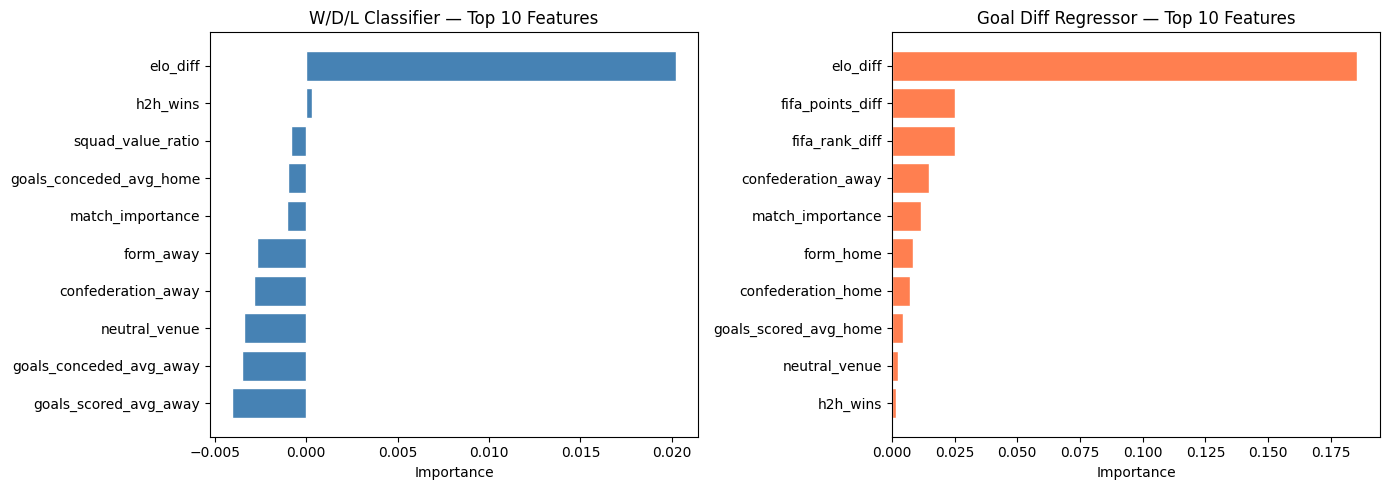

Feature importance plot saved to models/feature_importance.png


In [8]:
# Feature importance — top 10 for each model
fi_clf = predictor_clf.feature_importance(clf_val).head(10)
fi_reg = predictor_reg.feature_importance(reg_val).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(fi_clf.index[::-1], fi_clf["importance"][::-1], color="steelblue", edgecolor="white")
axes[0].set_title("W/D/L Classifier — Top 10 Features")
axes[0].set_xlabel("Importance")

axes[1].barh(fi_reg.index[::-1], fi_reg["importance"][::-1], color="coral", edgecolor="white")
axes[1].set_title("Goal Diff Regressor — Top 10 Features")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.savefig("../models/feature_importance.png", dpi=100, bbox_inches="tight")
plt.show()
print("Feature importance plot saved to models/feature_importance.png")